Loading datasets...
Processing data...
Generating visualizations...


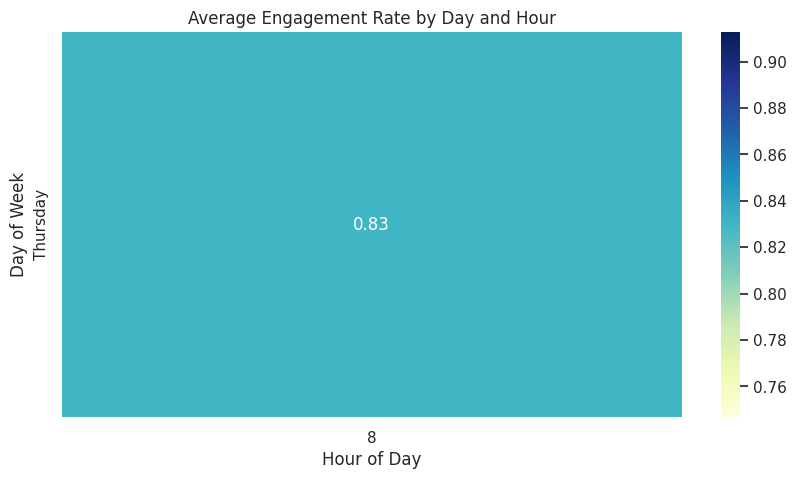

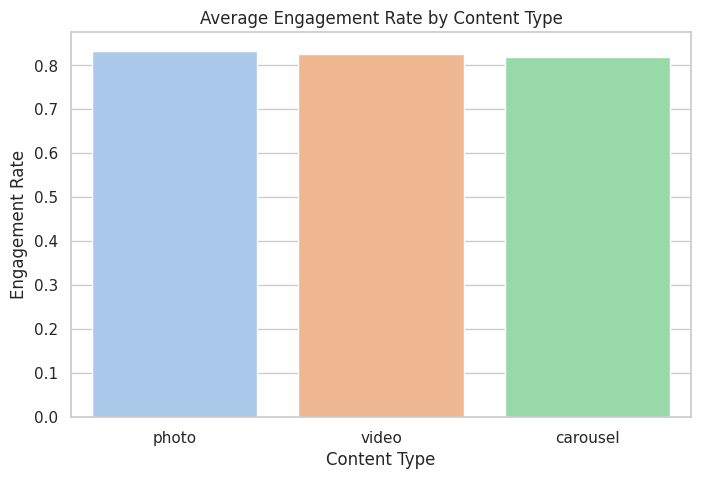

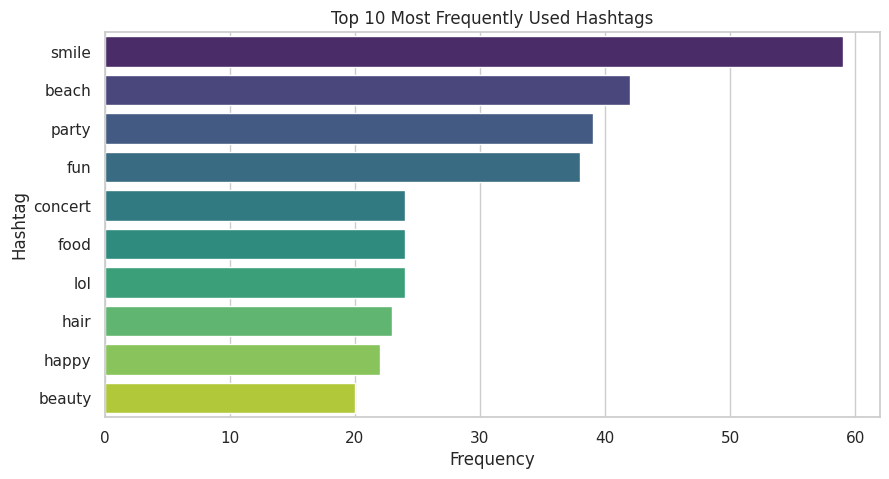

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 1. Load the Datasets
# ==========================================
print("Loading datasets...")
comments = pd.read_csv('comments.csv')
follows = pd.read_csv('follows.csv')
likes = pd.read_csv('likes.csv')
photo_tags = pd.read_csv('photo_tags.csv')
photos = pd.read_csv('photos.csv')
tags = pd.read_csv('tags.csv')
users = pd.read_csv('users.csv')

# Clean column names (strip trailing/leading spaces to avoid KeyErrors)
for df in [comments, follows, likes, photo_tags, photos, tags, users]:
    df.columns = [str(c).strip() for c in df.columns]

# ==========================================
# 2. Compute Engagement Metrics
# ==========================================
print("Processing data...")
# Calculate followers per user
followers_count = follows.groupby('followee').size().reset_index(name='followers')
followers_count.rename(columns={'followee': 'user_id'}, inplace=True)

# Likes per photo
likes_count = likes.groupby('photo').size().reset_index(name='like_count')

# Comments per photo
comments_count = comments.groupby('Photo id').size().reset_index(name='comment_count')
comments_count.rename(columns={'Photo id': 'photo'}, inplace=True)

# Merge photos with likes and comments
photos_eng = photos.merge(likes_count, left_on='id', right_on='photo', how='left').drop(columns=['photo', 'image link'])
photos_eng = photos_eng.merge(comments_count, left_on='id', right_on='photo', how='left').drop(columns=['photo'])
photos_eng['like_count'].fillna(0, inplace=True)
photos_eng['comment_count'].fillna(0, inplace=True)

# Merge with user followers to calculate engagement rate
photos_eng = photos_eng.merge(followers_count, left_on='user ID', right_on='user_id', how='left')
photos_eng['followers'].fillna(1, inplace=True) # Avoid division by zero
photos_eng['engagement_rate'] = (photos_eng['like_count'] + photos_eng['comment_count']) / photos_eng['followers']

# ==========================================
# 3. Analyze Posting Schedule
# ==========================================
# Parse datetime in photos
photos_eng['created dat'] = pd.to_datetime(photos_eng['created dat'], errors='coerce', dayfirst=True)
photos_eng = photos_eng.dropna(subset=['created dat'])
photos_eng['hour'] = photos_eng['created dat'].dt.hour
photos_eng['day_of_week'] = photos_eng['created dat'].dt.day_name()

# Set order for days of the week
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
photos_eng['day_of_week'] = pd.Categorical(photos_eng['day_of_week'], categories=days_order, ordered=True)

# ==========================================
# 4. Analyze Hashtags
# ==========================================
# Merge photo_tags and tags to get actual text
hashtag_data = photo_tags.merge(tags, left_on='tag ID', right_on='id', suffixes=('_pt', '_t'))
top_hashtags = hashtag_data['tag text'].value_counts().head(10).reset_index()
top_hashtags.columns = ['Hashtag', 'Frequency']

# ==========================================
# 5. Build Visualizations
# ==========================================
print("Generating visualizations...")
sns.set_theme(style="whitegrid")

# Visual A: Posting Schedule Heatmap
plt.figure(figsize=(10, 5))
heatmap_data = photos_eng.pivot_table(index='day_of_week', columns='hour', values='engagement_rate', aggfunc='mean')
if not heatmap_data.empty:
    sns.heatmap(heatmap_data, cmap='YlGnBu', annot=True, fmt=".2f")
    plt.title('Average Engagement Rate by Day and Hour')
    plt.xlabel('Hour of Day')
    plt.ylabel('Day of Week')
    plt.show()

# Visual B: Content Type Engagement
plt.figure(figsize=(8, 5))
sns.barplot(x='photo type', y='engagement_rate', data=photos_eng, errorbar=None, palette='pastel')
plt.title('Average Engagement Rate by Content Type')
plt.xlabel('Content Type')
plt.ylabel('Engagement Rate')
plt.show()

# Visual C: Top Hashtags
plt.figure(figsize=(10, 5))
sns.barplot(x='Frequency', y='Hashtag', data=top_hashtags, palette='viridis')
plt.title('Top 10 Most Frequently Used Hashtags')
plt.xlabel('Frequency')
plt.ylabel('Hashtag')
plt.show()